# 02_train.ipynb: chạy thí nghiệm ESC-50 (dùng chung cả nhóm)

1. Mở notebook trên Colab/Kaggle, bật **GPU T4** (Runtime → Change runtime type).
2. Ở **Cell 2**, chỉ sửa `EXP_ID` và `FOLDS`. Không cần chỉnh gì khác.
3. Chọn `Runtime → Run all`. Fold nào đã có JSON thì tự bỏ qua, nên Colab ngắt giữa chừng cứ chạy lại.
4. Không sửa `CFG` hay bất kỳ siêu tham số nào (muốn đổi phải báo nhóm trưởng và đổi cho cả 5 EXP).
5. Đọc phần **CHẾ ĐỘ** và **Thành phần** in ra ở Cell 3 để biết đang chạy hướng nào.

**Hai hướng chạy (`MODE` ở Cell 2; `"auto"` là mặc định, `"real"` ép chạy thật và báo lỗi nếu thiếu, `"fake"` ép chạy giả):**
- **Cache thật**: cần `esc50/data/ESC-50-master/cache/logmel64.pt` hoặc `logmel128.pt` và, với EXP2, EXP4, EXP5, hàm `specaug_batch` trong `src/data_lib.py`. Đủ thì chạy 60 epoch, kết quả ghi vào `results/` và `checkpoints/` trên Drive. Fold được chia bằng `get_splits` (nếu chưa import được `src/data_lib.py` thì dùng hàm tương đương theo C3, kết quả trùng nhau).
- **Cache giả**: tự dùng khi thiếu cache hoặc `specaug_batch`. Cache nhỏ (250 mẫu, nên không dùng `get_splits` vì hàm đó kiểm tra đúng 1200/400/400), 2 epoch, ghi vào thư mục tạm, chỉ để thử code, không dùng cho báo cáo.

`configs/base.yaml`có thì đọc, không có thì dùng `CFG` mặc định của C7. Khi chạy thật mà YAML khác C7 hoặc bảng C8, notebook dừng và báo lỗi.

In [2]:
import os, sys, subprocess

REPO_URL = "https://github.com/maian268/DeepLearning_Team.git"
BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules


def _find_project(start):
    d = os.path.abspath(start)
    while True:
        if os.path.exists(os.path.join(d, "src", "train_lib.py")):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            return None
        d = parent


if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_DIR = "/content/DeepLearning_Team"
    if not os.path.exists(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
                        "--branch", BRANCH, REPO_URL, REPO_DIR], check=True)
        subprocess.run(["git", "-C", REPO_DIR, "sparse-checkout", "set", "DOANCUOIKY"],
                       check=True)
    else:
        subprocess.run(["git", "-C", REPO_DIR, "pull"], check=True)
    PROJECT_DIR = os.path.join(REPO_DIR, "DOANCUOIKY", "ESC50")
else:
    PROJECT_DIR = _find_project(os.getcwd())
    if PROJECT_DIR is None:
        raise FileNotFoundError("Không thấy src/train_lib.py; hãy mở notebook trong thư mục repo ESC50.")

%pip install -q scikit-learn pyyaml pandas matplotlib gdown

sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))
sys.path.insert(0, PROJECT_DIR)
print("PROJECT_DIR =", PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR = /content/DeepLearning_Team/DOANCUOIKY/ESC50


In [3]:
EXP_ID = 2
FOLDS = [1, 2, 3, 4, 5]
MODE = "auto"

DRIVE_ROOT = "/content/drive/MyDrive/esc50"
DATA_DIR = f"{DRIVE_ROOT}/data/ESC-50-master"
CACHE_DIR = f"{DATA_DIR}/cache"
RESULT_DIR = f"{DRIVE_ROOT}/results"
CKPT_DIR = f"{DRIVE_ROOT}/checkpoints"
FIG_DIR = f"{DRIVE_ROOT}/figures"

EXPERIMENTS = {
    1: ("CNN", 64, False),
    2: ("CNN", 64, True),
    3: ("CNN", 128, False),
    4: ("CNN", 128, True),
    5: ("CRNN", 128, True),
    6: ("CRNN", 128, False),
}
assert EXP_ID in EXPERIMENTS, f"EXP_ID phải thuộc {sorted(EXPERIMENTS)}"
assert all(f in (1, 2, 3, 4, 5) for f in FOLDS), "FOLDS chỉ gồm các số 1..5"
assert MODE in ("auto", "real", "fake"), "MODE phải là auto, real hoặc fake"

In [4]:
import math
import tempfile
import train_lib
from train_lib import CFG, load_config, run_experiment

CONFIG_DIR = os.path.join(PROJECT_DIR, "configs")
yaml_files = [p for p in (os.path.join(CONFIG_DIR, "base.yaml"),
                          os.path.join(CONFIG_DIR, f"exp{EXP_ID}.yaml"))
              if os.path.exists(p)]
cfg = load_config(*yaml_files)

arch, n_mels, specaug = EXPERIMENTS[EXP_ID]
arch = cfg.get("arch", arch)
n_mels = int(cfg.get("n_mels", n_mels))
specaug = bool(cfg.get("specaug", specaug))


def load_data_lib():
    try:
        from src.data_lib import get_splits, specaug_batch
        return get_splits, specaug_batch, None
    except Exception as e:
        return None, None, f"{type(e).__name__}: {e}"


def same_value(a, b):
    if isinstance(a, (int, float)) and isinstance(b, (int, float)) \
            and not isinstance(a, bool) and not isinstance(b, bool):
        return math.isclose(a, b, rel_tol=1e-9, abs_tol=1e-12)
    return a == b


cache_name = f"logmel{n_mels}.pt"
have_cache = os.path.exists(os.path.join(CACHE_DIR, cache_name))
get_splits_real, specaug_fn_real, datalib_err = load_data_lib()
have_specaug = (not specaug) or specaug_fn_real is not None

missing = []
if not have_cache:
    missing.append(f"cache {cache_name}")
if not have_specaug:
    missing.append(f"specaug_batch ({datalib_err})")

if MODE == "real" and missing:
    raise FileNotFoundError("Thiếu: " + ", ".join(missing))
USE_FAKE_CACHE = MODE == "fake" or (MODE == "auto" and bool(missing))

if USE_FAKE_CACHE:
    _tmp = tempfile.mkdtemp(prefix="esc50_fake_")
    CACHE_DIR, RESULT_DIR, CKPT_DIR, FIG_DIR = (
        os.path.join(_tmp, n) for n in ("cache", "results", "checkpoints", "figures"))
    cfg = dict(cfg, max_epochs=2)
else:
    if (arch, n_mels, specaug) != EXPERIMENTS[EXP_ID]:
        raise ValueError(f"EXP{EXP_ID} trong YAML ({arch}, {n_mels}, {specaug}) "
                         f"khác bảng C8 {EXPERIMENTS[EXP_ID]}")
    diffs = {k: (cfg[k], CFG[k]) for k in CFG if not same_value(cfg[k], CFG[k])}
    if diffs:
        raise ValueError(f"Siêu tham số khác C7 (YAML, C7): {diffs}. Muốn đổi phải báo nhóm trưởng.")

if USE_FAKE_CACHE:
    reason = ", ".join(missing) if missing else "MODE = fake"
    print(f"CHẾ ĐỘ: CACHE GIẢ (thiếu: {reason}). 2 epoch, kết quả không ghi vào Drive.")
else:
    print("CHẾ ĐỘ: CACHE THẬT")
print("Thành phần:")
print(f"  cache thật {cache_name}: {'có' if have_cache else 'THIẾU'}")
if specaug:
    print(f"  specaug_batch (src/data_lib.py): {'có' if have_specaug else 'THIẾU'}")
print(f"  get_splits (src/data_lib.py): {'có' if get_splits_real is not None else 'THIẾU, dùng split_indices (cùng quy tắc C3)'}")
print("  YAML:", [os.path.basename(p) for p in yaml_files] or "không có, dùng CFG mặc định (C7)")
print(f"EXP{EXP_ID}: arch={arch}, n_mels={n_mels}, specaug={specaug}, folds={FOLDS}")
print("RESULT_DIR =", RESULT_DIR)

CHẾ ĐỘ: CACHE GIẢ (thiếu: specaug_batch (ModuleNotFoundError: No module named 'src.data_lib')). 2 epoch, kết quả không ghi vào Drive.
Thành phần:
  cache thật logmel64.pt: có
  specaug_batch (src/data_lib.py): THIẾU
  get_splits (src/data_lib.py): THIẾU, dùng split_indices (cùng quy tắc C3)
  YAML: ['base.yaml']
EXP2: arch=CNN, n_mels=64, specaug=True, folds=[1, 2, 3, 4, 5]
RESULT_DIR = /tmp/esc50_fake_d9d791ss/results


In [5]:
import torch


def make_fake_cache(n_mels, cache_dir, per_fold=50):
    os.makedirs(cache_dir, exist_ok=True)
    n = 5 * per_fold
    g = torch.Generator().manual_seed(0)
    y = torch.arange(n) % 50
    cache = dict(
        X=torch.randn(n, 1, n_mels, 216, generator=g),
        y=y.to(torch.int64),
        fold=(torch.arange(n) // per_fold + 1).to(torch.int64),
        filenames=[f"fake_{i}.wav" for i in range(n)],
        classes=[f"class_{i}" for i in range(50)],
    )
    torch.save(cache, os.path.join(cache_dir, f"logmel{n_mels}.pt"))


def fallback_specaug(x, n_mels):
    out = x
    b, _, f_dim, t_dim = x.shape
    max_f = 8 if n_mels == 64 else 16
    for dim_size, max_w, axis in ((f_dim, max_f, 2), (t_dim, 24, 3)):
        for _ in range(2):
            w = torch.randint(0, max_w + 1, (b,), device=x.device)
            start = (torch.rand(b, device=x.device) * (dim_size - w + 1)).long()
            pos = torch.arange(dim_size, device=x.device)[None, :]
            mask = (pos >= start[:, None]) & (pos < (start + w)[:, None])
            shape = [b, 1, 1, 1]
            shape[axis] = dim_size
            out = out.masked_fill(mask.view(*shape), 0.0)
    return out


def get_specaug_fn(n_mels):
    if specaug_fn_real is not None:
        return lambda x: specaug_fn_real(x, n_mels=n_mels, training=True)
    if USE_FAKE_CACHE:
        return lambda x: fallback_specaug(x, n_mels)
    raise RuntimeError("Không import được specaug_batch từ src/data_lib.py")


if USE_FAKE_CACHE:
    make_fake_cache(n_mels, CACHE_DIR)
    split_fn = None
else:
    split_fn = get_splits_real
print("Chia fold:", "get_splits (Quyên)" if split_fn is not None else "split_indices (cùng quy tắc C3)")

specaug_fn = get_specaug_fn(n_mels) if specaug else None

results = {}
for fold in FOLDS:
    print(f"\n=== EXP{EXP_ID} | fold {fold} | {arch} | {n_mels} bins | specaug={specaug} ===")
    results[fold] = run_experiment(
        EXP_ID, arch, n_mels, specaug, fold, cfg=cfg,
        cache_dir=CACHE_DIR, results_dir=RESULT_DIR, ckpt_dir=CKPT_DIR,
        specaug_fn=specaug_fn, split_fn=split_fn)

Chia fold: split_indices (cùng quy tắc C3)

=== EXP2 | fold 1 | CNN | 64 bins | specaug=True ===
ep 01 | lr 1.0e-03 | train 4.205/0.007 | val 3.934/0.020
ep 02 | lr 1.0e-03 | train 3.996/0.013 | val 4.146/0.020
exp2_fold1: acc=0.020, macro_f1=0.001, best_epoch=1, params=1,185,490

=== EXP2 | fold 2 | CNN | 64 bins | specaug=True ===
ep 01 | lr 1.0e-03 | train 4.200/0.000 | val 3.935/0.020
ep 02 | lr 1.0e-03 | train 3.995/0.020 | val 4.259/0.020
exp2_fold2: acc=0.020, macro_f1=0.001, best_epoch=1, params=1,185,490

=== EXP2 | fold 3 | CNN | 64 bins | specaug=True ===
ep 01 | lr 1.0e-03 | train 4.191/0.000 | val 3.934/0.020
ep 02 | lr 1.0e-03 | train 4.002/0.033 | val 4.254/0.020
exp2_fold3: acc=0.020, macro_f1=0.001, best_epoch=1, params=1,185,490

=== EXP2 | fold 4 | CNN | 64 bins | specaug=True ===
ep 01 | lr 1.0e-03 | train 4.183/0.000 | val 3.934/0.020
ep 02 | lr 1.0e-03 | train 3.998/0.027 | val 4.151/0.020
exp2_fold4: acc=0.020, macro_f1=0.001, best_epoch=1, params=1,185,490

=== 

,fold,acc,macro_f1,val_acc_best,best_epoch,train_time_s,params
0,1,2.0,0.1,2.0,1,48,1185490
1,2,2.0,0.1,2.0,1,44,1185490
2,3,2.0,0.1,2.0,1,43,1185490
3,4,2.0,0.1,2.0,1,43,1185490
4,5,2.0,0.1,2.0,1,43,1185490


EXP2 (5/5 fold)  Accuracy: 2,0 ± 0,0  |  Macro-F1: 0,1 ± 0,0


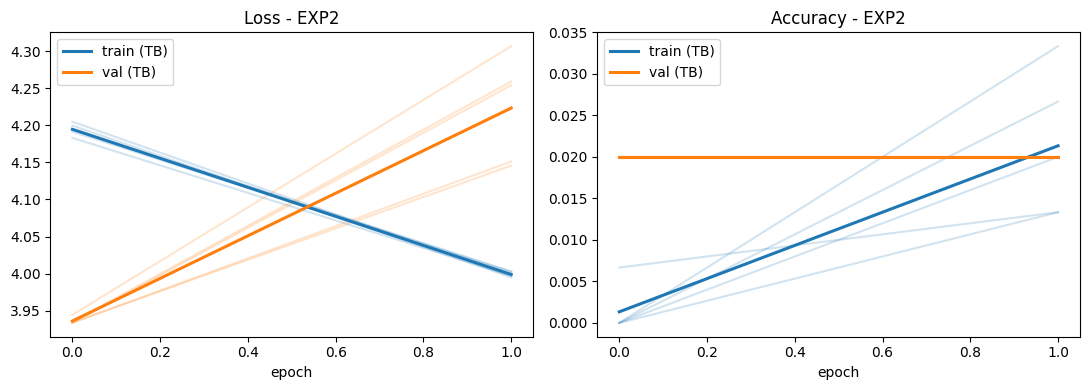

Đã lưu hình: /tmp/esc50_fake_d9d791ss/figures/fig6_curves_exp2.png


In [6]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rows, hist = [], {}
for fold in range(1, 6):
    p = os.path.join(RESULT_DIR, f"exp{EXP_ID}_fold{fold}.json")
    if not os.path.exists(p):
        continue
    with open(p, encoding="utf-8") as f:
        r = json.load(f)
    rows.append(dict(fold=fold, acc=100 * r["acc"], macro_f1=100 * r["macro_f1"],
                     val_acc_best=100 * r["val_acc_best"], best_epoch=r["best_epoch"],
                     train_time_s=round(r["train_time_s"]), params=r["params"]))
    hist[fold] = r["history"]

if not rows:
    print("Chưa có kết quả nào trong", RESULT_DIR)
else:
    df = pd.DataFrame(rows).round(1)
    display(df)

    def fmt(v):
        m = float(np.mean(v))
        s = float(np.std(v, ddof=1)) if len(v) > 1 else float("nan")
        return f"{m:.1f} ± {s:.1f}".replace(".", ",")

    print(f"EXP{EXP_ID} ({len(rows)}/5 fold)  Accuracy: {fmt(df['acc'])}  |  Macro-F1: {fmt(df['macro_f1'])}")
    if not USE_FAKE_CACHE:
        m_acc = df["acc"].mean()
        if m_acc < 5 or m_acc > 90:
            print(f"CẢNH BÁO: accuracy TB {m_acc:.1f}% bất thường "
                  "(≈2% nghi lỗi nhãn/quên chuẩn hóa; >90% nghi rò rỉ dữ liệu).")

    def mean_curve(key):
        length = max(len(h) for h in hist.values())
        arr = np.full((len(hist), length), np.nan)
        for i, h in enumerate(hist.values()):
            arr[i, :len(h)] = [e[key] for e in h]
        return np.nanmean(arr, axis=0)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, (tr_key, va_key, title) in zip(axes, (("train_loss", "val_loss", "Loss"),
                                                  ("train_acc", "val_acc", "Accuracy"))):
        for h in hist.values():
            ax.plot([e[tr_key] for e in h], color="tab:blue", alpha=0.2)
            ax.plot([e[va_key] for e in h], color="tab:orange", alpha=0.2)
        ax.plot(mean_curve(tr_key), color="tab:blue", lw=2.2, label="train (TB)")
        ax.plot(mean_curve(va_key), color="tab:orange", lw=2.2, label="val (TB)")
        ax.set_xlabel("epoch")
        ax.set_title(f"{title} - EXP{EXP_ID}")
        ax.legend()
    plt.tight_layout()
    os.makedirs(FIG_DIR, exist_ok=True)
    fig_path = os.path.join(FIG_DIR, f"fig6_curves_exp{EXP_ID}.png")
    plt.savefig(fig_path, dpi=200)
    plt.show()
    print("Đã lưu hình:", fig_path)